# Text-to-Image and Image-to-Text problem solving.
This notebook highlights techniques used to finetune U-Net models, and we explore a use case where bigger isn't always better. ✨
- Teaching a visual concept to a Text to image model with Stable Diffusion
- Naming that concept and making it usable in text prompts with Textual Inversion

## Prerequisites to run this notebook:


1. GPU compute - for parallelized training. Pay as you go is fine ~$11
2. A Huggingface token saved as `HF_TOKEN` in the environment variables (free)
3. A google drive with max 8 photos of yourself, pets, family, people and things that represent meaning to you.

This demo's set up instructions describe how to run this in Google Colab with Pay-as-you-go compute for parallelization of the training process. I have not tried running it on CPU.

All models used are open weights; your data and fine tuning stays on the machine running the code. It's possible to download the model directly, but using the HF API we save ourselves storage costs.

### Check compute
Check top right hand corner, connect to a T4 hosted runtime.

In [1]:
from subprocess import getoutput
from IPython.display import HTML
from IPython.display import clear_output
import time
import torch

s = getoutput('nvidia-smi')
if 'T4' in s:
  gpu = 'T4'
elif 'P100' in s:
  gpu = 'P100'
elif 'V100' in s:
  gpu = 'V100'
elif 'A100' in s:
  gpu = 'A100'

if gpu=='T4'or gpu=='P100'or gpu=='V100'or gpu=='A100':
  print('Selected setup: ' +gpu)
else:
  print('It seems that your GPU is not supported at the moment')

Selected setup: T4


### Check HF Token
See if you can load the model

In [2]:
# Import needed libraries
from transformers import CLIPImageProcessor, CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, DDPMScheduler, PNDMScheduler, StableDiffusionPipeline, UNet2DConditionModel

from tqdm.auto import tqdm

`StableDiffusionPipeline` is an end-to-end inference pipeline that you can use to generate images from text with just a few lines of code.

Read the descriptions below to see the evolution.

| Model | Architecture | Hub repo ID | Diffusers class|
|---|---|---|---|
| Stable Diffusion 1.5 (CNN)| U-Net (~0.9B), one CLIP text encoder| `stable-diffusion-v1-5/stable-diffusion-v1-5` | `StableDiffusionPipeline`, good for cheap digital art, can run on very small. + largest ecosystem of LoRAs, textual inversions, ControlNets, and fine tunes|
|SDXL (CNN) | U-Net (~2.6B), two text encoders | `stabilityai/stable-diffusion-xl-base-1.0` | `StableDiffusionXLPipeline`, can do photorealism|
|Stable Diffusion 3 | MMDiT transformer (~2B), three text encoders including T5 | `stabilityai/stable-diffusion-3-medium-diffusers` | `StableDiffusion3Pipeline`, can render text; handles text and image tokens jointly |
|  Stable Diffusion 3.5 | MMDiT transformer, (~2.5B in medium, ~8B in large, turbo variants) | `stabilityai/stable-diffusion-3.5-large`, and `-medium`, `-large-turbo`| `StableDiffusion3Pipeline` | Improved quality and diversity; medium size is practical on smaller GPUs |
| FLUX.1 | Rectified-flow transformer (~12B) | `black-forest-labs/FLUX.1-dev` or `-schnell` | `FluxPipeline` | Good at following complex prompts, adhering to anatomy, and Schnell works in 1 to 4 steps |


<br>As of 2024, Stable Diffusion models adopted a Transformer backbone, similar to text transformers using an attention mechanism. This made them require much more training data, and gave them multimodal capabilities. They could now continue to improve with more parameters, and remain performant on more complex prompts. This is what Chat GPT uses today.

~90 minutes to train
<br><br>

Stable Diffusion CNN backbones will never be able to render text correctly, but they have an advantage when it comes to speed and training data requirements. You can gain more control with fewer data.

~15 minutes to train
<br><br>


In [4]:
#@markdown `pretrained_model_name_or_path` which Stable Diffusion checkpoint you want to use
pretrained_model_name_or_path = "CompVis/stable-diffusion-v1-4" #@param ["CompVis/stable-diffusion-v1-4", "stabilityai/sd-turbo", "stable-diffusion-v1-5/stable-diffusion-v1-5"] {allow-input: true}

In [7]:
#@title Load the Stable Diffusion model
#@markdown The [pre-trained model](https://huggingface.co/CompVis/stable-diffusion-v1-3-diffusers/tree/main) includes all the components required to setup a complete diffusion pipeline. They are stored in the following folders:
#@markdown - `text_encoder`: Stable Diffusion uses CLIP, but other diffusion models may use other encoders such as `BERT`.
#@markdown - `tokenizer`. It must match the one used by the `text_encoder` model.
#@markdown - `scheduler`: The scheduling algorithm used to progressively add noise to the image during training.
#@markdown - `unet`: The model used to generate the latent representation of the input.
#@markdown - `vae`: Autoencoder module that we'll use to decode latent representations into real images.<br><br>
#@markdown We can load the components by referring to the folder they were saved, using the `subfolder` argument to `from_pretrained`.
text_encoder = CLIPTextModel.from_pretrained(
    pretrained_model_name_or_path,
    subfolder="text_encoder"
)

tokenizer = CLIPTokenizer.from_pretrained(
    pretrained_model_name_or_path,
    subfolder="tokenizer",
)

noise_scheduler = DDPMScheduler.from_config(
    pretrained_model_name_or_path,
    subfolder="scheduler"
)

vae = AutoencoderKL.from_pretrained(
    pretrained_model_name_or_path,
    subfolder="vae",
    torch_dtype=torch.float16
)

unet = UNet2DConditionModel.from_pretrained(
    pretrained_model_name_or_path,
    subfolder="unet",
    torch_dtype=torch.float16
)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [8]:
# see which models are compatible with our Pipeline
from huggingface_hub import HfApi
models = HfApi().list_models(
    filter=["diffusers", "diffusers:StableDiffusionPipeline"],
    sort="downloads",
    limit=20,
)
for m in models:
    print(m.id)

stable-diffusion-v1-5/stable-diffusion-v1-5
Lykon/dreamshaper-7
stabilityai/sd-turbo
CompVis/stable-diffusion-v1-4
SG161222/Realistic_Vision_V5.1_noVAE
Lykon/DreamShaper
stablediffusionapi/revanimated
optimum-intel-internal-testing/tiny-stable-diffusion-torch
Lykon/dreamshaper-8
SG161222/Realistic_Vision_V6.0_B1_noVAE
CompVis/stable-diffusion-v1-1
stablediffusionapi/juggernaut-reborn
Manojb/stable-diffusion-2-1-base
botp/stable-diffusion-v1-5
stablediffusionapi/chilloutmix
gsdf/Counterfeit-V2.5
optimum-intel-internal-testing/tiny-random-stable-diffusion-with-safety-checker
stablediffusionapi/majicmixrealistic
Lykon/AnyLoRA
segmind/tiny-sd


### Initiate the StableDiffusionPipeline

In [9]:
pipe = StableDiffusionPipeline.from_pretrained(pretrained_model_name_or_path, use_safetensors=True)

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

In [10]:
# Move pipe to GPU for faster inference
if torch.cuda.is_available():
    device=torch.device("cuda")
elif torch.backends.mps.is_available():
    device=torch.device("mps")

pipe = pipe.to(device)

In [11]:
vae = vae.to(device)
text_encoder = text_encoder.to(device)
unet = unet.to(device)

### Check Google Drive sample

In [39]:
import os
import PIL
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [42]:
#@markdown `images_path` is a path to directory containing the training images. It could
images_path = "gdrive/MyDrive/ai-community/nmo-sample" #@param {type:"string"}
while not os.path.exists(str(images_path)):
  print('The images_path specified does not exist, use the colab file explorer to copy the path :')
  images_path=input("")
save_path = images_path

In [43]:
def image_grid(imgs, rows, cols):
    assert len(imgs) == rows*cols

    w, h = imgs[0].size
    grid = PIL.Image.new('RGB', size=(cols*w, rows*h))
    grid_w, grid_h = grid.size

    for i, img in enumerate(imgs):
        grid.paste(img, box=(i%cols*w, i//cols*h))
    return grid

In [44]:
images = []
for file_path in os.listdir(save_path):
  try:
      image_path = os.path.join(save_path, file_path)
      images.append(PIL.Image.open(image_path).resize((512, 512)))
  except:
    print(f"{image_path} is not a valid image, please make sure to remove this file from the directory otherwise the training could fail.")
image_grid(images, 1, len(images))

Output hidden; open in https://colab.research.google.com to view.

# If everything ran, congrats! Skip re-running the next few cells and keep going.
If not, don't troubleshoot now. Follow along with the presentation.

In [45]:
# @markdown Optional, Find the meening of your love, career, and finance reading:

import requests
url = "https://tarotapi.dev/api/v1/cards/"
resp = requests.get(url)


# Stable Diffusion at work:
No need to re-run these cells

  0%|          | 0/50 [00:00<?, ?it/s]

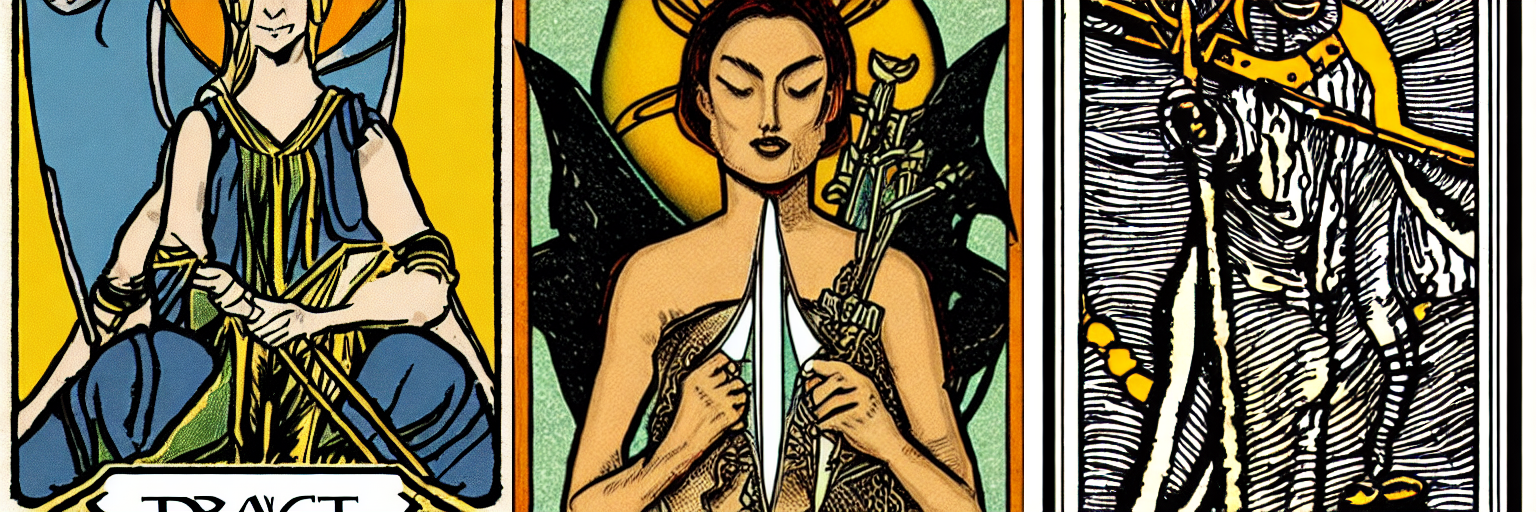

In [47]:
num_images = 3
prompt = ["draw a tarot card for this muse"] * num_images

images = pipe(prompt).images

grid = image_grid(images, rows=1, cols=3)
grid


In [ ]:
[x for x in resp.json()['cards'] if x.get("name") == "Four of Cups"][0]['meaning_up']

'Weariness, disgust, aversion, imaginary vexations, as if the wine of this world had caused satiety only; another wine, as if a fairy gift, is now offered the wastrel, but he sees no consolation therein. This is also a card of blended pleasure.'

In [ ]:
[x for x in resp.json()['cards'] if x.get("name") == "The High Priestess"][0]['meaning_up']

'Secrets, mystery, the future as yet unrevealed; the woman who interests the Querent, if male; the Querent herself, if female; silence, tenacity; mystery, wisdom, science.'

In [ ]:
[x for x in resp.json()['cards'] if x.get("name") == "Fortitude"][0]['meaning_up']

'Power, energy, action, courage, magnanimity; also complete success and honours.'

***

# How did it do that?
You can begin re-running cells again
## Stable Diffusion is a U-shaped Convolutional Neural Net <br>
In computer vision, there are various tasks
- Image classification
- Object detection
- Localization

But what about image segmentation? A pixel-by-pixel classification into an object category.
- Boundaries
- Spacial Relation

Once we could encode this, we could begin generating images. Similar to tokenization and chunking for LLMs, the first U-Nets used overlapping patches of pixels as tokens.

Looking at the U diagram, we see
- the Encoder Side, translating the image into latent space,
- the Decoder side, translating latent space back into image

There are two concepts to know when describing the U.
- high-level features - context; or abstraction of what's in the whole picture
- low-level features - resolution; local, fine-grained patterns

The top part of the U represents low-level features, and the bottom of the U represents high-level features as it downsamples.

Meaning the encoder first focuses on the tiny details, then zooms out and learns its place within the broader picture.

And the decoder first reconstructs the broader context and works its way into the finer details, leveraging the Skip Connections (arrows). These represent how the encoder’s low-level feature maps directly across to the matching decoder layers, so the upsampling path is informed by relevant information lost in the downsampling, ie: sharp boundaries.

<img src="https://arxiv.org/html/1505.04597v1/u-net-illustration-correct-scale2.svg">
<br>

Source: [U-Net: Convolutional Networks for Biomedical Image Segmentation, 2015](https://zslpublications.onlinelibrary.wiley.com/doi/10.1002/rse2.111)

# But we prompted it with text and it created an image, how?

When you submit a prompt, it gets tokenized by a CLIP model in a format the UNET model can take as input. These embeddings will be used to condition the UNet model. This conditioningn is

CLIP is Contrastive Language–Image Pre-training, Stable Diffusion does **not** train the text-encoder during training.

Image Segmentation with UNET, combined with a way to dynamically name it, is what gives us text driven image generation.

<br>
<img src="https://assets.insightmediagroup.io/media/wp-content/uploads/2023/10/1HHSfAfmRshkETpqZx7CKkA.png"><br>

Source: [Learning Transferrable Visual Models from Natural Language Supervision, 2021](https://doi.org/10.48550/arXiv.2103.00020)<br><br>
At Inference, the StableDiffusionPipeline tokenizes the prompt and starting with a completely random image - iteratively *denoises* it into what the prompt describes.

In each iteration, the output of the U-Net, called a noise residual, computes a denoised latent image representation via a scheduler algorithm.

Additional information: [Visual Guide to Stable Diffusion](https://www.reddit.com/r/StableDiffusion/comments/13belgg/a_quick_visual_guide_to_whats_actually_happening/)<br><br>

# Problem statement
### A compelling game of universal symbolism is too general and abstract to apply to me.

I'm talking about the Tarot.
- It's agnostic, popularized in port cities where goods, perspectives, and ideas were exchanged.
- There are no copyrights on the imagery meant to represent the cyclical nature of a person's journey through life.  
- Evidence of a rich cultural tradition where interpretations of randomness and vagueness have profoundly impacted humans.

## But I don't get it.

- I am introspective, self aware, and open to using a tool to broaden my perspective as I navigate life.
- Relying on the interpretaton guides provided in books feels so abstract, I can't follow how it would map to my life.
- Psychics speak athoritatively, but I find myself unable to buy into it. I'm skeptical and distracted.

## Why is this the perfect AI use case?
- No copyrights
- Straight forward data sharing consent model
- Hallucinations are a feature, not a bug
- No false pretense of authority as there is with therapy, companionship, etc.
- Empowering the user to be their own guide

## What will we learn?
- Larger models =/= better.
- Working off of complete information is invasive, and not always building the trust we want.
- Complex prompts are not always feasible or needed.

Hopefully by understanding the tools we can use to accomplish our goals in latent space, we can design practical, resonant solutions.

# Teach the model a new concept (fine-tuning with textual inversion)
Execute this this sequence of cells to run the training process. The whole process may take from 1-4 hours. (Open this block if you are interested in how this process works under the hood or if you want to change advanced training settings or hyperparameters)

## Data

In [46]:
import numpy as np
import torch
import torch.nn.functional as F
import torch.utils.checkpoint
from torch.utils.data import Dataset

In [20]:
#@title Settings for your newly created concept
#@markdown `what_to_teach`: what is it that you are teaching? `object` enables you to teach the model a new object to be used, `style` allows you to teach the model a new style one can use.
what_to_teach = "object" #@param ["object", "style"]
#@markdown `placeholder_token` is the token you are going to use to represent your new concept (so when you prompt the model, you will say "A `<my-placeholder-token>` in an amusement park"). We use angle brackets to differentiate a token from other words/tokens, to avoid collision.
placeholder_token = "<muse>" #@param {type:"string"}
#@markdown `initializer_token` is a word that can summarise what your new concept is, to be used as a starting point
initializer_token = "muse" #@param {type:"string"}

In [48]:
#@title Setup the prompt templates for training
imagenet_templates_small = [
    "a photo of a {}",
    "a rendering of a {}",
    "a cropped photo of the {}",
    "the photo of a {}",
    "a photo of a clean {}",
    "a photo of a dirty {}",
    "a dark photo of the {}",
    "a photo of my {}",
    "a photo of the cool {}",
    "a close-up photo of a {}",
    "a bright photo of the {}",
    "a cropped photo of a {}",
    "a photo of the {}",
    "a good photo of the {}",
    "a photo of one {}",
    "a close-up photo of the {}",
    "a rendition of the {}",
    "a photo of the clean {}",
    "a rendition of a {}",
    "a photo of a nice {}",
    "a good photo of a {}",
    "a photo of the nice {}",
    "a photo of the small {}",
    "a photo of the weird {}",
    "a photo of the large {}",
    "a photo of a cool {}",
    "a photo of a small {}",
]

imagenet_style_templates_small = [
    "a painting in the style of {}",
    "a rendering in the style of {}",
    "a cropped painting in the style of {}",
    "the painting in the style of {}",
    "a clean painting in the style of {}",
    "a dirty painting in the style of {}",
    "a dark painting in the style of {}",
    "a picture in the style of {}",
    "a cool painting in the style of {}",
    "a close-up painting in the style of {}",
    "a bright painting in the style of {}",
    "a cropped painting in the style of {}",
    "a good painting in the style of {}",
    "a close-up painting in the style of {}",
    "a rendition in the style of {}",
    "a nice painting in the style of {}",
    "a small painting in the style of {}",
    "a weird painting in the style of {}",
    "a large painting in the style of {}",
]

In [49]:
from torchvision import transforms
from accelerate import Accelerator
from accelerate.logging import get_logger
from accelerate.utils import set_seed

import random

In [50]:
#@title Setup the dataset
class TextualInversionDataset(Dataset):
    def __init__(
        self,
        data_root,
        tokenizer,
        learnable_property="object",  # [object, style]
        size=512,
        repeats=100,
        interpolation="bicubic",
        flip_p=0.5,
        set="train",
        placeholder_token="*",
        center_crop=True,
    ):

        self.data_root = data_root
        self.tokenizer = tokenizer
        self.learnable_property = learnable_property
        self.size = size
        self.placeholder_token = placeholder_token
        self.center_crop = center_crop
        self.flip_p = flip_p

        self.image_paths = [os.path.join(self.data_root, file_path) for file_path in os.listdir(self.data_root)]

        self.num_images = len(self.image_paths)
        self._length = self.num_images

        if set == "train":
            self._length = self.num_images * repeats

        self.interpolation = {
            "bilinear": PIL.Image.BILINEAR,
            "bicubic": PIL.Image.BICUBIC,
            "lanczos": PIL.Image.LANCZOS,
        }[interpolation]

        self.templates = imagenet_style_templates_small if learnable_property == "style" else imagenet_templates_small
        self.flip_transform = transforms.RandomHorizontalFlip(p=self.flip_p)

    def __len__(self):
        return self._length

    def __getitem__(self, i):
        example = {}
        image = PIL.Image.open(self.image_paths[i % self.num_images])

        if not image.mode == "RGB":
            image = image.convert("RGB")

        placeholder_string = self.placeholder_token
        text = random.choice(self.templates).format(placeholder_string)

        example["input_ids"] = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=self.tokenizer.model_max_length,
            return_tensors="pt",
        ).input_ids[0]

        # default to score-sde preprocessing
        img = np.array(image).astype(np.uint8)

        if self.center_crop:
            crop = min(img.shape[0], img.shape[1])
            h, w, = (
                img.shape[0],
                img.shape[1],
            )
            img = img[(h - crop) // 2 : (h + crop) // 2, (w - crop) // 2 : (w + crop) // 2]

        image = PIL.Image.fromarray(img)
        image = image.resize((self.size, self.size), resample=self.interpolation)

        image = self.flip_transform(image)
        image = np.array(image).astype(np.uint8)
        image = (image / 127.5 - 1.0).astype(np.float32)

        example["pixel_values"] = torch.from_numpy(image).permute(2, 0, 1)
        return example

## Model

In [51]:
import itertools

In [52]:
#@title Load the tokenizer and add the placeholder token as a additional special token.
tokenizer = CLIPTokenizer.from_pretrained(
    pretrained_model_name_or_path,
    subfolder="tokenizer",
)

# Add the placeholder token in tokenizer
num_added_tokens = tokenizer.add_tokens(placeholder_token)
if num_added_tokens == 0:
    raise ValueError(
        f"The tokenizer already contains the token {placeholder_token}. Please pass a different"
        " `placeholder_token` that is not already in the tokenizer."
    )

In [53]:
#@title Get token ids for our placeholder and initializer token. This code block will complain if initializer string is not a single token
# Convert the initializer_token, placeholder_token to ids
token_ids = tokenizer.encode(initializer_token, add_special_tokens=False)
# Check if initializer_token is a single token or a sequence of tokens
if len(token_ids) > 1:
    raise ValueError("The initializer token must be a single token.")

initializer_token_id = token_ids[0]
placeholder_token_id = tokenizer.convert_tokens_to_ids(placeholder_token)

We have added the `placeholder_token` in the `tokenizer` so we resize the token embeddings here, this will a new embedding vector in the token embeddings for our `placeholder_token`

In [54]:
text_encoder.resize_token_embeddings(len(tokenizer))

Embedding(49409, 768)

Initialise the newly added placeholder token with the embeddings of the initializer token

In [28]:
token_embeds = text_encoder.get_input_embeddings().weight.data
token_embeds[placeholder_token_id] = token_embeds[initializer_token_id]

In Textual-Inversion we only train the newly added embedding vector, so lets freeze rest of the model parameters here

In [55]:
def freeze_params(params):
    for param in params:
        param.requires_grad = False

# Freeze vae and unet
freeze_params(vae.parameters())
freeze_params(unet.parameters())
# Freeze all parameters except for the token embeddings in text encoder
params_to_freeze = itertools.chain(
    text_encoder.encoder.parameters(),
    text_encoder.final_layer_norm.parameters(),
    text_encoder.embeddings.position_embedding.parameters(),
)
freeze_params(params_to_freeze)

# Training

In [57]:
save_path

'gdrive/MyDrive/ai-community/nmo-sample'

In [58]:
# @title Create training data

train_dataset = TextualInversionDataset(
      data_root=save_path,
      tokenizer=tokenizer,
      size=vae.sample_size,
      placeholder_token=placeholder_token,
      repeats=100,
      learnable_property=what_to_teach, #Option selected above between object and style
      center_crop=False,
      set="train",
)

/tmp/ipykernel_37206/3094099165.py:6: FutureWarning: Accessing config attribute `sample_size` directly via 'AutoencoderKL' object attribute is deprecated. Please access 'sample_size' over 'AutoencoderKL's config object instead, e.g. 'unet.config.sample_size'.
  size=vae.sample_size,


In [59]:
# @title Create dataloader
def create_dataloader(train_batch_size=1):
    return torch.utils.data.DataLoader(train_dataset, batch_size=train_batch_size, shuffle=True)

In [62]:
# @title Set training hyperparameters
# @markdown Define hyperparameters for our training
# @markdown If you are not happy with your results, you can tune the `learning_rate` and the `max_train_steps`

hyperparameters = {
    "learning_rate": 2e-4,
    "scale_lr": True,
    "max_train_steps": 3000,
    "save_steps": 250,
    "train_batch_size": 4,
    "gradient_accumulation_steps": 1,
    "gradient_checkpointing": True,
    "mixed_precision": "fp16",
    "seed": 42,
    "output_dir": "sd-concept-output"
}
!mkdir -p sd-concept-output

In [63]:
#@title Training checkpointing helpers
logger = get_logger(__name__)
RESUME_FILE = "resume_state.pt"

def save_progress(text_encoder, placeholder_token_id, accelerator, save_path):
    logger.info("Saving embeddings")
    learned_embeds = accelerator.unwrap_model(text_encoder).get_input_embeddings().weight[placeholder_token_id]
    learned_embeds_dict = {placeholder_token: learned_embeds.detach().cpu()}
    torch.save(learned_embeds_dict, save_path)

def save_checkpoint(text_encoder, optimizer, placeholder_token_id, accelerator, global_step, output_dir):
    """Saves the learned embedding plus the optimizer state for that one row, so training can resume."""
    os.makedirs(output_dir, exist_ok=True)
    weight = accelerator.unwrap_model(text_encoder).get_input_embeddings().weight

    # Optimizer state for just the placeholder row (the full state is ~400MB and mostly unused)
    opt_state = {}
    state = optimizer.state.get(weight, {})
    for k, v in state.items():
        if torch.is_tensor(v) and v.dim() > 0:
            opt_state[k] = v[placeholder_token_id].detach().cpu()
        elif torch.is_tensor(v):
            opt_state[k] = v.detach().cpu()
        else:
            opt_state[k] = v

    payload = {
        "global_step": global_step,
        "placeholder_token": placeholder_token,
        "embedding": weight[placeholder_token_id].detach().cpu(),
        "opt_state": opt_state,
    }
    tmp_path = os.path.join(output_dir, RESUME_FILE + ".tmp")
    torch.save(payload, tmp_path)
    os.replace(tmp_path, os.path.join(output_dir, RESUME_FILE))  # atomic: never leaves a half-written file

    # Also keep a small, embedding-only file per checkpoint for comparing steps later
    save_progress(
        text_encoder, placeholder_token_id, accelerator,
        os.path.join(output_dir, f"learned_embeds-step-{global_step}.bin"),
    )

def load_checkpoint(text_encoder, optimizer, placeholder_token_id, accelerator, output_dir):
    """Restores embedding + optimizer state. Returns the step to resume from (0 if no checkpoint)."""
    path = os.path.join(output_dir, RESUME_FILE)
    if not os.path.exists(path):
        logger.info("No checkpoint found, starting from step 0")
        return 0

    ckpt = torch.load(path, map_location="cpu")
    weight = accelerator.unwrap_model(text_encoder).get_input_embeddings().weight
    device = weight.device

    with torch.no_grad():
        weight[placeholder_token_id] = ckpt["embedding"].to(device, dtype=weight.dtype)

    # Rebuild the AdamW state: zeros everywhere except the placeholder row
    saved = ckpt["opt_state"]
    if saved:
        new_state = {}
        for k, v in saved.items():
            if torch.is_tensor(v) and v.dim() > 0:
                full = torch.zeros_like(weight, memory_format=torch.preserve_format)
                full[placeholder_token_id] = v.to(device, dtype=weight.dtype)
                new_state[k] = full
            elif torch.is_tensor(v):
                new_state[k] = v.to(device)
            else:
                new_state[k] = v
        optimizer.state[weight] = new_state

    logger.info(f"Resumed from step {ckpt['global_step']}")
    return ckpt["global_step"]

In [64]:
#@title Training function

def training_function(text_encoder, vae, unet):
    train_batch_size = hyperparameters["train_batch_size"]
    gradient_accumulation_steps = hyperparameters["gradient_accumulation_steps"]
    learning_rate = hyperparameters["learning_rate"]
    max_train_steps = hyperparameters["max_train_steps"]
    output_dir = hyperparameters["output_dir"]
    gradient_checkpointing = hyperparameters["gradient_checkpointing"]

    accelerator = Accelerator(
        gradient_accumulation_steps=gradient_accumulation_steps,
        mixed_precision=hyperparameters["mixed_precision"]
    )

    if gradient_checkpointing:
        text_encoder.gradient_checkpointing_enable()
        unet.enable_gradient_checkpointing()

    train_dataloader = create_dataloader(train_batch_size)

    if hyperparameters["scale_lr"]:
        learning_rate = (
            learning_rate * gradient_accumulation_steps * train_batch_size * accelerator.num_processes
        )

    # Initialize the optimizer
    optimizer = torch.optim.AdamW(
        text_encoder.get_input_embeddings().parameters(),  # only optimize the embeddings
        lr=learning_rate,
    )

    text_encoder, optimizer, train_dataloader = accelerator.prepare(
        text_encoder, optimizer, train_dataloader
    )

    weight_dtype = torch.float32
    if accelerator.mixed_precision == "fp16":
        weight_dtype = torch.float16
    elif accelerator.mixed_precision == "bf16":
        weight_dtype = torch.bfloat16

    # Move vae and unet to device
    vae.to(accelerator.device, dtype=weight_dtype)
    unet.to(accelerator.device, dtype=weight_dtype)

    # Keep vae in eval mode as we don't train it
    vae.eval()
    # Keep unet in train mode to enable gradient checkpointing
    unet.train()


    # We need to recalculate our total training steps as the size of the training dataloader may have changed.
    num_update_steps_per_epoch = math.ceil(len(train_dataloader) / gradient_accumulation_steps)
    num_train_epochs = math.ceil(max_train_steps / num_update_steps_per_epoch)

    # Train!
    total_batch_size = train_batch_size * accelerator.num_processes * gradient_accumulation_steps

    logger.info("***** Running training *****")
    logger.info(f"  Num examples = {len(train_dataset)}")
    logger.info(f"  Instantaneous batch size per device = {train_batch_size}")
    logger.info(f"  Total train batch size (w. parallel, distributed & accumulation) = {total_batch_size}")
    logger.info(f"  Gradient Accumulation steps = {gradient_accumulation_steps}")
    logger.info(f"  Total optimization steps = {max_train_steps}")
    # Only show the progress bar once on each machine.
    progress_bar = tqdm(range(max_train_steps), disable=not accelerator.is_local_main_process)
    progress_bar.set_description("Steps")
    global_step = 0

    for epoch in range(num_train_epochs):
        text_encoder.train()
        for step, batch in enumerate(train_dataloader):
            with accelerator.accumulate(text_encoder):
                # Convert images to latent space
                latents = vae.encode(batch["pixel_values"].to(dtype=weight_dtype)).latent_dist.sample().detach()
                latents = latents * 0.18215

                # Sample noise that we'll add to the latents
                noise = torch.randn_like(latents)
                bsz = latents.shape[0]
                # Sample a random timestep for each image
                timesteps = torch.randint(0, noise_scheduler.num_train_timesteps, (bsz,), device=latents.device).long()

                # Add noise to the latents according to the noise magnitude at each timestep
                # (this is the forward diffusion process)
                noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

                # Get the text embedding for conditioning
                encoder_hidden_states = text_encoder(batch["input_ids"])[0]

                # Predict the noise residual
                noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states.to(weight_dtype)).sample

                 # Get the target for loss depending on the prediction type
                if noise_scheduler.config.prediction_type == "epsilon":
                    target = noise
                elif noise_scheduler.config.prediction_type == "v_prediction":
                    target = noise_scheduler.get_velocity(latents, noise, timesteps)
                else:
                    raise ValueError(f"Unknown prediction type {noise_scheduler.config.prediction_type}")

                loss = F.mse_loss(noise_pred, target, reduction="none").mean([1, 2, 3]).mean()
                accelerator.backward(loss)

                # Zero out the gradients for all token embeddings except the newly added
                # embeddings for the concept, as we only want to optimize the concept embeddings
                if accelerator.num_processes > 1:
                    grads = text_encoder.module.get_input_embeddings().weight.grad
                else:
                    grads = text_encoder.get_input_embeddings().weight.grad
                # Get the index for tokens that we want to zero the grads for
                index_grads_to_zero = torch.arange(len(tokenizer)) != placeholder_token_id
                grads.data[index_grads_to_zero, :] = grads.data[index_grads_to_zero, :].fill_(0)

                optimizer.step()
                optimizer.zero_grad()

            # Checks if the accelerator has performed an optimization step behind the scenes
            if accelerator.sync_gradients:
                progress_bar.update(1)
                global_step += 1
                if global_step % hyperparameters["save_steps"] == 0:
                    save_path = os.path.join(output_dir, f"learned_embeds-step-{global_step}.bin")
                    save_progress(text_encoder, placeholder_token_id, accelerator, save_path)

            logs = {"loss": loss.detach().item()}
            progress_bar.set_postfix(**logs)

            if global_step >= max_train_steps:
                break

        accelerator.wait_for_everyone()


    # Create the pipeline using using the trained modules and save it.
    if accelerator.is_main_process:
        pipeline = StableDiffusionPipeline.from_pretrained(
            pretrained_model_name_or_path,
            text_encoder=accelerator.unwrap_model(text_encoder),
            tokenizer=tokenizer,
            vae=vae,
            unet=unet,
        )
        pipeline.save_pretrained(output_dir)
        # Also save the newly trained embeddings
        save_path = os.path.join(output_dir, f"learned_embeds.bin")
        save_progress(text_encoder, placeholder_token_id, accelerator, save_path)

# 🏁 Train time

In [65]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [ ]:
import math
import accelerate
accelerate.notebook_launcher(training_function, args=(text_encoder, vae, unet))

for param in itertools.chain(unet.parameters(), text_encoder.parameters()):
  if param.grad is not None:
    del param.grad  # free some memory
  torch.cuda.empty_cache()

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Launching training on one GPU.


  0%|          | 0/3000 [00:00<?, ?it/s]

# Use trained model

In [ ]:

#@title Set up the pipeline
from diffusers import DPMSolverMultistepScheduler
pipe = StableDiffusionPipeline.from_pretrained(
    hyperparameters["output_dir"],
    scheduler=DPMSolverMultistepScheduler.from_pretrained(hyperparameters["output_dir"], subfolder="scheduler"),
    torch_dtype=torch.float16,
).to("cuda")

In [71]:
# emb = pipe.text_encoder.get_input_embeddings().weight
# tid = pipe.tokenizer.convert_tokens_to_ids("<muse>")
# with torch.no_grad():
#     emb[tid] *= 1.3

In [62]:
[x for x in resp.json()['cards'] if x.get("name") == "Four of Cups"][0]

{'name': 'Four of Cups',
 'name_short': 'cu04',
 'value': 'four',
 'value_int': 4,
 'suit': 'cups',
 'type': 'minor',
 'meaning_up': 'Weariness, disgust, aversion, imaginary vexations, as if the wine of this world had caused satiety only; another wine, as if a fairy gift, is now offered the wastrel, but he sees no consolation therein. This is also a card of blended pleasure.',
 'meaning_rev': 'Novelty, presage, new instruction, new relations.',
 'desc': 'A young man is seated under a tree and contemplates three cups set on the grass before him; an arm issuing from a cloud offers him another cup. His expression notwithstanding is one of discontent with his environment.'}

In [54]:
cups4_desc = [x for x in resp.json()['cards'] if x.get("name") == "Four of Cups"][0]['desc']

A <muse>-style Hermit, holding a source of light, stands alone on the summit of a mountain.

  0%|          | 0/2 [00:00<?, ?it/s]

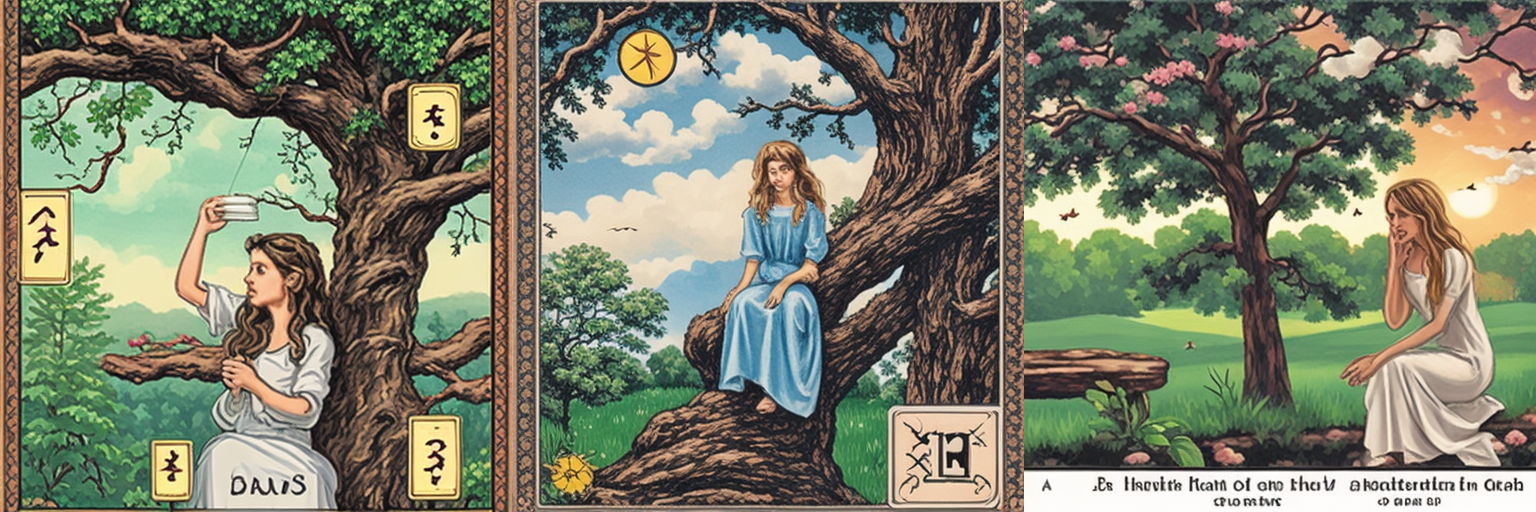

In [78]:
#@title Run the Stable Diffusion pipeline
#@markdown Don't forget to use the placeholder token in your prompt.
#@markdown CLIP has a 77 token prompt limit.
prompt = "A 3 of cups tarot card featuring a <muse>-style youth, sheltered by a tree, contemplating 3 cups before her. An arm from a cloud offers her another cup. She is discontent with the <muse>-style environment" #@param {type:"string"}

num_samples = 3 #@param {type:"number"}
num_rows = 1 #@param {type:"number"}
#@markdown Classifier-free guidance controls how strongly the model follows your text prompt during generation.
#@markdown - Low values (1-3) looser, more varied and creative, but the image may ignore parts of the prompt
#@markdown - Typical values (7-8) for SD 1.5/2.1: a good balance of prompt adherence and image quality.
#@markdown - High values (12+): follows the prompt very literally, but images tend to get oversaturated, overcontrasted and artifacty.
#@markdown - A value of 1 or less: best for SD-Turbo; the guidance term does nothing, so the pipeline skips the unconditioned pass entirely. That makes generation about twice as fast.

cfg = 0 #@param {type:"number"}

all_images = []
for _ in range(num_rows):
  emb = pipe.text_encoder.get_input_embeddings().weight
  tid = pipe.tokenizer.convert_tokens_to_ids("<muse>")
  with torch.no_grad():
      emb[tid] *= 1.3
      images = pipe([prompt] * num_samples, num_inference_steps=2, guidance_scale=cfg).images
      all_images.extend(images)

grid = image_grid(all_images, num_rows, num_samples)
grid

In [ ]:
#@title Run the Stable Diffusion pipeline
#@markdown Don't forget to use the placeholder token in your prompt

prompt = "The child of life on a white horse, holds a red flag, representing the blood of renewal while a smiling sun shines down on her, representing accomplishment and abundance in the style of \u003Cmtn>" #@param {type:"string"}

num_samples = 3 #@param {type:"number"}
num_rows = 1 #@param {type:"number"}

all_images = []
for _ in range(num_rows):
    images = pipe([prompt] * num_samples, num_inference_steps=30, guidance_scale=7.5).images
    all_images.extend(images)

grid = image_grid(all_images, num_rows, num_samples)
grid

In [ ]:
#@title Run the Stable Diffusion pipeline
#@markdown Don't forget to use the placeholder token in your prompt

prompt = "The child of life on a white horse, holds a red flag, representing the blood of renewal while a smiling sun shines down on her, representing accomplishment and abundance in the style of \u003Cmtn>" #@param {type:"string"}

num_samples = 3 #@param {type:"number"}
num_rows = 1 #@param {type:"number"}

all_images = []
for _ in range(num_rows):
    images = pipe([prompt] * num_samples, num_inference_steps=30, guidance_scale=7.5).images
    all_images.extend(images)

grid = image_grid(all_images, num_rows, num_samples)
grid

# Resources
- https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/sd_textual_inversion_training.ipynb
- https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/stable_diffusion.ipynb
-